# Stage 10 – Driving-cycle construction

**Purpose.** Join the real segments selected in Stage 9 into **one driving cycle per environment**:
a speed–time trace (1 Hz) that represents how the EV is driven in that environment.

**How a cycle is built.**
1. **Order the segments** so the speed at the end of one segment is as close as possible to the speed at
   the start of the next (the total "jump" at the joins is minimised). Among equally smooth orders, a
   fixed random shuffle decides, so congested and flowing pieces are mixed instead of grouped.
2. **Join them.** Where the jump at a join is small (≤ 3.6 km/h, i.e. at most 1 m/s² for one second),
   the segments are simply placed one after the other. Where it is larger (e.g. a "partial" segment that
   starts while moving), a short **bridge** is inserted that changes speed at 1 m/s².
3. Every cycle **starts and ends at rest**, like standard cycles (WLTP, NEDC).
4. The recorded segments are **never changed**: no smoothing, scaling or cutting. Only the bridges are
   added, and they are marked, counted and limited to ≤ 5 % of the cycle.

**Output** (`outputs/stage10_driving_cycles/`):
- `<Environment>_cycle.csv`: **time_s, speed_kmh** (the deliverable required by the methodology)
- `<Environment>_cycle_detailed.csv`: plus source segment, cluster and observed/interpolated flag
- `<Environment>_segment_order.csv`, `ordering_and_joins.csv`, `cycle_vs_construction_driving.csv`
- speed–time plots: `driving_cycles.png` and one `<Environment>_cycle.png` per cycle

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

BASE = Path("/content/drive/MyDrive/Colab Notebooks/Component01")
SELECTED = BASE / "intermediate/stage9_selected/selected_segments.csv"   # Stage 9: which real segments
TRACES = BASE / "intermediate/stage9_selected/selected_traces.csv"       # Stage 9: their 1 Hz speed traces
FEATURES = BASE / "intermediate/stage7_features/segment_features.csv"    # Stage 7: for the target statistics
SPLIT = BASE / "outputs/stage9_selection/trip_split.csv"                 # Stage 9: construction / held-out trips
CYCLE_DIR = BASE / "outputs/stage10_driving_cycles"                      # final cycles (time, speed) + plots + report
CYCLE_DIR.mkdir(parents=True, exist_ok=True)

for p in (SELECTED, TRACES, FEATURES, SPLIT):
    if not p.exists():
        raise FileNotFoundError(f"{p} not found. Is Google Drive mounted, and have Stages 7-9 been run?")
selected = pd.read_csv(SELECTED)
traces = pd.read_csv(TRACES).sort_values(["seg_uid", "t_s"])
features = pd.read_csv(FEATURES)
split = pd.read_csv(SPLIT)
print(f"{len(selected)} selected segments ({traces['seg_uid'].nunique()} traces, {len(traces):,} s) "
      f"for environments: {selected['environment'].value_counts().to_dict()}")

26 selected segments (26 traces, 3,491 s) for environments: {'Suburban': 11, 'Urban': 11, 'Expressway': 4}


In [2]:
CFG = {
    "stop_kmh": 2.0,                  # same stop definition as Stages 6-7 (a cycle starts and ends below this)
    "transition_rate_ms2": 1.0,       # speed change used to bridge a join (moderate; urban mean acceleration ~0.5 m/s2)
    "max_transition_share": 0.05,     # at most 5 % of a cycle may be bridging seconds (the rest is recorded driving)
    "max_abs_accel_ms2": 5.0,         # physical limit, same as Stages 2-3 and 7
    "accel_threshold_ms2": 0.1,       # cruise / accelerate / decelerate threshold, same as Stage 7
    "min_stop_s": 3,                  # same as Stages 6-7
    "random_state": 42,               # fixed shuffle so equally smooth orders are picked reproducibly
    "target_duration_s": {"Urban": 1200, "Suburban": 600, "Expressway": 1800, "Intercity": 1200, "Rural": 1200},
}
JOIN_STEP_KMH = CFG["transition_rate_ms2"] * 3.6   # a speed difference up to this is a normal 1-second change
pd.Series({**CFG, "join_step_kmh": JOIN_STEP_KMH}, name="value").to_frame()

,value
stop_kmh,2.0
transition_rate_ms2,1.0
max_transition_share,0.05
max_abs_accel_ms2,5.0
accel_threshold_ms2,0.1
min_stop_s,3
random_state,42
target_duration_s,"{'Urban': 1200, 'Suburban': 600, 'Expressway':..."
join_step_kmh,3.6


In [3]:
def join_cost(order, v0, v1):
    """Total speed jump of a sequence: from rest to the first segment, between segments, and back to rest."""
    jumps = [v0[order[0]]] + [abs(v1[a] - v0[b]) for a, b in zip(order[:-1], order[1:])] + [v1[order[-1]]]
    return float(np.sum(jumps))


def best_order(ids, v0, v1, seed):
    """Order that minimises the speed jumps at the joins: shuffled start (reproducible), then local search
    with swaps and moves until no change improves the cost. Ties keep the shuffled (random) order."""
    order = list(np.random.default_rng(seed).permutation(ids))
    cost = join_cost(order, v0, v1)
    improved = True
    while improved:
        improved = False
        n = len(order)
        for i in range(n):
            for j in range(n):
                if i == j:
                    continue
                for move in ("swap", "insert"):
                    o = order.copy()
                    if move == "swap":
                        o[i], o[j] = o[j], o[i]
                    else:
                        o.insert(j, o.pop(i))
                    c = join_cost(o, v0, v1)
                    if c < cost - 1e-9:
                        order, cost, improved = o, c, True
    return order, cost


def bridge(a, b):
    """Speeds strictly between a and b, changing by at most JOIN_STEP_KMH per second (empty if not needed)."""
    n = int(np.ceil(abs(b - a) / JOIN_STEP_KMH)) - 1
    return np.linspace(a, b, n + 2)[1:-1] if n > 0 else np.array([])


def build_cycle(order, speed_of, cluster_of):
    """Concatenate the real segments in order; insert short bridges only where a join would jump too much."""
    parts, prev = [], 0.0                                   # every cycle starts from rest
    for u in order:
        v = speed_of[u]
        br = bridge(prev, v[0])
        if len(br):
            parts.append(pd.DataFrame({"speed_kmh": br, "source": "transition", "cluster_id": "-"}))
        parts.append(pd.DataFrame({"speed_kmh": v, "source": u, "cluster_id": cluster_of[u]}))
        prev = v[-1]
    br = bridge(prev, 0.0)                                  # and ends at rest
    if len(br):
        parts.append(pd.DataFrame({"speed_kmh": br, "source": "transition", "cluster_id": "-"}))
    if prev >= CFG["stop_kmh"] or len(br):
        parts.append(pd.DataFrame({"speed_kmh": [0.0], "source": "transition", "cluster_id": "-"}))
    c = pd.concat(parts, ignore_index=True)
    c.insert(0, "time_s", np.arange(len(c)))
    c["speed_kmh"] = c["speed_kmh"].round(3)
    return c


def cycle_stats(v):
    """Statistics of a speed trace, with the same definitions as Stage 7."""
    v = np.asarray(v, float)
    a = np.gradient(v / 3.6)
    moving = v >= CFG["stop_kmh"]
    th = CFG["accel_threshold_ms2"]
    still = np.r_[False, ~moving, False].astype(int)
    d = np.diff(still)
    n_stops = int(((np.where(d == -1)[0] - np.where(d == 1)[0]) >= CFG["min_stop_s"]).sum())
    dist_km = v.sum() / 3600
    return pd.Series({
        "duration_s": len(v), "distance_km": dist_km, "mean_speed_kmh": v.mean(), "max_speed_kmh": v.max(),
        "idle_share": (~moving).mean(), "cruise_share": (moving & (np.abs(a) < th)).mean(),
        "accel_share": (moving & (a >= th)).mean(), "stops_per_km": n_stops / dist_km if dist_km else np.nan,
        "rpa_ms2": (v / 3.6 * np.clip(a, 0, None)).sum() / (dist_km * 1000) if dist_km else np.nan,
        "std_accel_ms2": a[moving].std() if moving.any() else 0.0,
        "max_accel_ms2": a.max(), "max_decel_ms2": -a.min(),
    })


def target_stats(env):
    """The same statistics for ALL construction driving of an environment (what the cycle should reproduce)."""
    con_trips = set(split.loc[split["set"] == "construction", "trip_id"])
    E = features[(features["environment"] == env) & features["trip_id"].isin(con_trips)]
    T, D, mov = E["duration_s"].sum(), E["distance_km"].sum(), E["moving_s"].sum()
    return pd.Series({
        "duration_s": T, "distance_km": D, "mean_speed_kmh": D / T * 3600, "max_speed_kmh": E["max_speed_kmh"].quantile(0.95),
        "idle_share": E["stopped_s"].sum() / T, "cruise_share": (E["cruise_share"] * E["duration_s"]).sum() / T,
        "accel_share": (E["accel_share"] * E["duration_s"]).sum() / T, "stops_per_km": E["n_stops"].sum() / D,
        "rpa_ms2": (E["rpa_ms2"] * E["distance_km"]).sum() / D,
        "std_accel_ms2": np.sqrt((E["std_accel_ms2"] ** 2 * E["moving_s"]).sum() / mov),
        "max_accel_ms2": E["max_accel_ms2"].quantile(0.95), "max_decel_ms2": E["max_decel_ms2"].quantile(0.95),
    })

In [4]:
order_env = ["Urban", "Suburban", "Intercity", "Rural", "Expressway"]
envs = [e for e in order_env if e in set(selected["environment"])]
speed_of = {u: t["speed_kmh"].values.astype(float) for u, t in traces.groupby("seg_uid")}
flag_of = {u: t["speed_flag"].values for u, t in traces.groupby("seg_uid")}
cluster_of = selected.set_index("seg_uid")["cluster_id"].to_dict()

cycles, order_rows = {}, []
for e in envs:
    ids = selected.loc[selected["environment"] == e, "seg_uid"].tolist()
    v0 = {u: speed_of[u][0] for u in ids}
    v1 = {u: speed_of[u][-1] for u in ids}
    as_selected = join_cost(ids, v0, v1)
    rng = np.random.default_rng(CFG["random_state"])
    random_costs = [join_cost(list(rng.permutation(ids)), v0, v1) for _ in range(200)]
    order, cost = best_order(ids, v0, v1, CFG["random_state"])
    c = build_cycle(order, speed_of, cluster_of)
    c["speed_flag"] = "transition"
    for u in order:
        c.loc[c["source"] == u, "speed_flag"] = flag_of[u]
    cycles[e] = c
    order_rows.append({"environment": e, "segments": len(ids), "join_jump_as_selected_kmh": round(as_selected, 1),
                       "join_jump_random_order_mean_kmh": round(float(np.mean(random_costs)), 1),
                       "join_jump_optimised_kmh": round(cost, 1),
                       "transition_s": int((c["source"] == "transition").sum()), "cycle_s": len(c)})
    pd.DataFrame({"position": range(1, len(order) + 1), "seg_uid": order,
                  "cluster_id": [cluster_of[u] for u in order],
                  "start_kmh": [round(v0[u], 1) for u in order], "end_kmh": [round(v1[u], 1) for u in order],
                  "duration_s": [len(speed_of[u]) for u in order]}).to_csv(CYCLE_DIR / f"{e}_segment_order.csv", index=False)

ordering = pd.DataFrame(order_rows).set_index("environment")
ordering["transition_share_%"] = (100 * ordering["transition_s"] / ordering["cycle_s"]).round(2)
ordering.to_csv(CYCLE_DIR / "ordering_and_joins.csv")
print("Total speed jump at the joins (km/h): order as selected vs. random vs. optimised; bridging seconds added")
ordering

Total speed jump at the joins (km/h): order as selected vs. random vs. optimised; bridging seconds added


,segments,join_jump_as_selected_kmh,join_jump_random_order_mean_kmh,join_jump_optimised_kmh,transition_s,cycle_s,transition_share_%
environment,,,,,,,
Urban,11,28.8,28.2,24.5,1,1216,0.08
Suburban,11,198.6,205.9,71.6,15,593,2.53
Expressway,4,12.3,148.3,11.6,1,1699,0.06


In [5]:
for e, c in cycles.items():
    c[["time_s", "speed_kmh"]].to_csv(CYCLE_DIR / f"{e}_cycle.csv", index=False)          # the deliverable: time, speed
    c.to_csv(CYCLE_DIR / f"{e}_cycle_detailed.csv", index=False)                         # + source segment, cluster, flag
    print(f"{e:10s}: {len(c):5d} s, {c['speed_kmh'].sum() / 3600:6.2f} km -> {e}_cycle.csv")

stats = pd.DataFrame({e: cycle_stats(c["speed_kmh"]) for e, c in cycles.items()}).T
targets = pd.DataFrame({e: target_stats(e) for e in cycles}).T
compare = []
for e in cycles:
    for s in ["mean_speed_kmh", "max_speed_kmh", "idle_share", "cruise_share", "accel_share",
              "stops_per_km", "rpa_ms2", "std_accel_ms2", "max_accel_ms2", "max_decel_ms2"]:
        t, v = targets.loc[e, s], stats.loc[e, s]
        compare.append({"environment": e, "statistic": s, "cycle": round(v, 3), "construction_driving": round(t, 3),
                        "difference_%": round(100 * (v - t) / t, 1) if t else np.nan})
compare = pd.DataFrame(compare)
compare.to_csv(CYCLE_DIR / "cycle_vs_construction_driving.csv", index=False)
print("\nCycle statistics vs. ALL construction driving of the same environment "
      "(max speed / max accel targets = 95th percentile of segments):")
display(compare.pivot(index="statistic", columns="environment", values="difference_%").round(1)
        .rename(columns=lambda x: f"{x} diff %"))
stats.round(3)

Urban     :  1216 s,   6.88 km -> Urban_cycle.csv
Suburban  :   593 s,   3.73 km -> Suburban_cycle.csv
Expressway:  1699 s,  36.25 km -> Expressway_cycle.csv

Cycle statistics vs. ALL construction driving of the same environment (max speed / max accel targets = 95th percentile of segments):


environment,Expressway diff %,Suburban diff %,Urban diff %
statistic,,,
accel_share,-6.4,-1.7,-0.5
cruise_share,1.1,-2.6,0.1
idle_share,8.3,0.8,1.5
max_accel_ms2,8.6,-10.3,-14.9
max_decel_ms2,27.2,-4.9,-1.8
max_speed_kmh,-0.7,-0.4,-1.2
mean_speed_kmh,0.5,1.2,-3.3
rpa_ms2,0.7,-5.8,-0.8
std_accel_ms2,10.5,6.0,-1.4


,duration_s,distance_km,mean_speed_kmh,max_speed_kmh,idle_share,cruise_share,accel_share,stops_per_km,rpa_ms2,std_accel_ms2,max_accel_ms2,max_decel_ms2
Urban,1216.0,6.875,20.354,49.999,0.139,0.318,0.272,1.600,0.147,0.495,1.673,2.010
Suburban,593.0,3.730,22.641,54.799,0.167,0.255,0.317,1.877,0.191,0.583,1.686,2.043
Expressway,1699.0,36.251,76.812,97.200,0.032,0.725,0.124,0.055,0.048,0.313,1.697,4.358


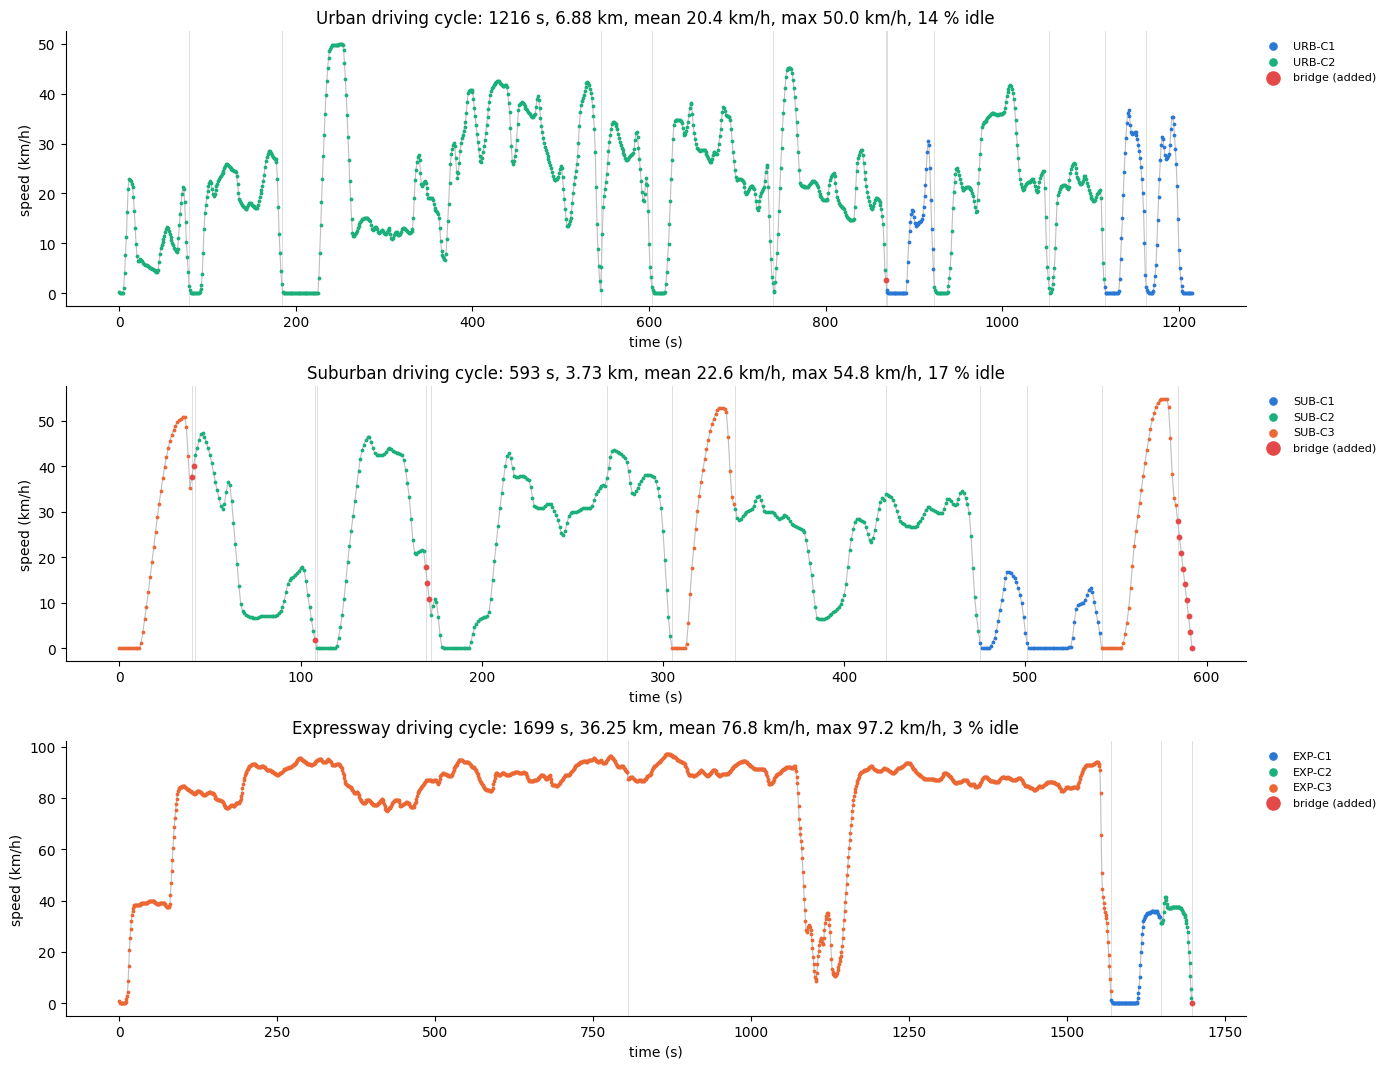

Saved one plot per cycle: ['Urban_cycle.png', 'Suburban_cycle.png', 'Expressway_cycle.png']


In [6]:
colors = {"transition": "#e34948"}
palette = ["#2a78d6", "#1baf7a", "#eb6834", "#6250d6", "#eda100", "#52514e"]
fig, axes = plt.subplots(len(cycles), 1, figsize=(14, 3.6 * len(cycles)), squeeze=False)
for ax, (e, c) in zip(axes[:, 0], cycles.items()):
    cl_ids = sorted(x for x in c["cluster_id"].unique() if x != "-")
    ax.plot(c["time_s"], c["speed_kmh"], color="0.75", lw=0.8, zorder=1)
    for i, cl in enumerate(cl_ids):
        m = c["cluster_id"] == cl
        ax.scatter(c.loc[m, "time_s"], c.loc[m, "speed_kmh"], s=3, color=palette[i % len(palette)], label=cl, zorder=2)
    t = c["source"] == "transition"
    ax.scatter(c.loc[t, "time_s"], c.loc[t, "speed_kmh"], s=10, color=colors["transition"], label="bridge (added)", zorder=3)
    for x in c.index[c["source"] != c["source"].shift()][1:]:
        ax.axvline(c.at[x, "time_s"], color="0.85", lw=0.6, zorder=0)
    s = stats.loc[e]
    ax.set(xlabel="time (s)", ylabel="speed (km/h)",
           title=f"{e} driving cycle: {int(s['duration_s'])} s, {s['distance_km']:.2f} km, mean {s['mean_speed_kmh']:.1f} km/h, "
                 f"max {s['max_speed_kmh']:.1f} km/h, {100 * s['idle_share']:.0f} % idle")
    ax.legend(fontsize=8, markerscale=3, loc="upper left", bbox_to_anchor=(1.005, 1), frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(CYCLE_DIR / "driving_cycles.png", dpi=150)
plt.show()

for e, c in cycles.items():                                   # one clean figure per cycle for the report
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(c["time_s"], c["speed_kmh"], color="#2a78d6", lw=1)
    ax.set(xlabel="time (s)", ylabel="speed (km/h)", title=f"{e} driving cycle (EV, synthetic test data)")
    ax.set_xlim(0, len(c)); ax.set_ylim(0, None)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(CYCLE_DIR / f"{e}_cycle.png", dpi=150)
    plt.close(fig)
print("Saved one plot per cycle:", [f"{e}_cycle.png" for e in cycles])

In [7]:
checks = {}
for e, c in cycles.items():
    v = c["speed_kmh"].values
    a = np.diff(v) / 3.6
    checks.setdefault("time runs 0, 1, 2 ... (1 s steps)", []).append(bool((c["time_s"].values == np.arange(len(c))).all()))
    checks.setdefault("starts and ends at rest", []).append(bool(v[0] < CFG["stop_kmh"] and v[-1] < CFG["stop_kmh"]))
    checks.setdefault("no missing or negative speed, max <= 200 km/h", []).append(
        bool(np.isfinite(v).all() and (v >= 0).all() and v.max() <= 200))
    checks.setdefault(f"|acceleration| <= {CFG['max_abs_accel_ms2']} m/s2 everywhere", []).append(
        bool(np.abs(a).max() <= CFG["max_abs_accel_ms2"]))
    joins = np.where(c["source"].values[1:] != c["source"].values[:-1])[0]
    checks.setdefault(f"no speed jump at a join larger than {JOIN_STEP_KMH:.1f} km/h", []).append(
        bool(len(joins) == 0 or np.abs(np.diff(v)[joins]).max() <= JOIN_STEP_KMH + 1e-6))
    ids = selected.loc[selected["environment"] == e, "seg_uid"]
    checks.setdefault("every selected segment used exactly once, complete and unchanged", []).append(all(
        (c["source"] == u).sum() == len(speed_of[u]) and np.allclose(c.loc[c["source"] == u, "speed_kmh"], speed_of[u], atol=1e-3)
        for u in ids) and set(c["source"]) - {"transition"} == set(ids))
    checks.setdefault(f"bridging seconds <= {100 * CFG['max_transition_share']:.0f} % of the cycle", []).append(
        bool((c["source"] == "transition").mean() <= CFG["max_transition_share"]))
    checks.setdefault("cycle length within +/-25 % of target", []).append(
        bool(abs(len(c) - CFG["target_duration_s"][e]) <= 0.25 * CFG["target_duration_s"][e]))
    saved = pd.read_csv(CYCLE_DIR / f"{e}_cycle.csv")
    checks.setdefault("saved CSV has exactly time_s, speed_kmh and matches", []).append(
        list(saved.columns) == ["time_s", "speed_kmh"] and np.allclose(saved["speed_kmh"], v))
checks["optimised order has no larger join jumps than the order as selected"] = [
    bool((ordering["join_jump_optimised_kmh"] <= ordering["join_jump_as_selected_kmh"] + 1e-6).all())]
verification = pd.DataFrame({k: [f"{sum(x)}/{len(x)}", "PASS" if all(x) else "CHECK"] for k, x in checks.items()},
                            index=["cycles passing", "result"]).T
verification

,cycles passing,result
"time runs 0, 1, 2 ... (1 s steps)",3/3,PASS
starts and ends at rest,3/3,PASS
"no missing or negative speed, max <= 200 km/h",3/3,PASS
|acceleration| <= 5.0 m/s2 everywhere,3/3,PASS
no speed jump at a join larger than 3.6 km/h,3/3,PASS
"every selected segment used exactly once, complete and unchanged",3/3,PASS
bridging seconds <= 5 % of the cycle,3/3,PASS
cycle length within +/-25 % of target,3/3,PASS
"saved CSV has exactly time_s, speed_kmh and matches",3/3,PASS
optimised order has no larger join jumps than the order as selected,1/1,PASS


In [8]:
print("STAGE 10 – DRIVING-CYCLE CONSTRUCTION: KEY RESULTS")
print("-" * 60)
for e, c in cycles.items():
    s = stats.loc[e]
    d = compare[compare["environment"] == e].set_index("statistic")["difference_%"]
    print(f"  {e:10s}: {int(s['duration_s'])} s, {s['distance_km']:.2f} km, mean {s['mean_speed_kmh']:.1f} km/h, "
          f"max {s['max_speed_kmh']:.1f} km/h, idle {100 * s['idle_share']:.1f} %, {ordering.loc[e, 'segments']} real segments, "
          f"{ordering.loc[e, 'transition_s']} bridging s ({ordering.loc[e, 'transition_share_%']} %)")
    print(f"              vs. construction driving: mean speed {d['mean_speed_kmh']:+.1f} %, idle {d['idle_share']:+.1f} %, "
          f"cruise {d['cruise_share']:+.1f} %, RPA {d['rpa_ms2']:+.1f} %")
missing = [e for e in order_env if e not in cycles]
if missing:
    print(f"No cycle for: {', '.join(missing)} (no data in this dataset - a coverage limitation)")
print(f"Files: {', '.join(f'{e}_cycle.csv' for e in cycles)} in {CYCLE_DIR}")
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 10 – DRIVING-CYCLE CONSTRUCTION: KEY RESULTS
------------------------------------------------------------
  Urban     : 1216 s, 6.88 km, mean 20.4 km/h, max 50.0 km/h, idle 13.9 %, 11 real segments, 1 bridging s (0.08 %)
              vs. construction driving: mean speed -3.3 %, idle +1.5 %, cruise +0.1 %, RPA -0.8 %
  Suburban  : 593 s, 3.73 km, mean 22.6 km/h, max 54.8 km/h, idle 16.7 %, 11 real segments, 15 bridging s (2.53 %)
              vs. construction driving: mean speed +1.2 %, idle +0.8 %, cruise -2.6 %, RPA -5.8 %
  Expressway: 1699 s, 36.25 km, mean 76.8 km/h, max 97.2 km/h, idle 3.2 %, 4 real segments, 1 bridging s (0.06 %)
              vs. construction driving: mean speed +0.5 %, idle +8.3 %, cruise +1.1 %, RPA +0.7 %
No cycle for: Intercity, Rural (no data in this dataset - a coverage limitation)
Files: Urban_cycle.csv, Suburban_cycle.csv, Expressway_cycle.csv in /content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage10_driving_cycles
Verification: all c